# Train Test Splits, Cross Validation, and Linear Regression

# Learning Objectives

- Explicarea diferenței dintre supraadaptarea și subadaptarea unui model
- Descrieți compromisurile bias-varianță
- Găsiți împărțirea optimă a seturilor de date de instruire și de testare, validarea încrucișată și complexitatea modelului în funcție de eroare
- Aplicarea unui model de regresie liniară pentru învățarea supravegheată

## Introduction

Vom lucra cu un set de date bazat pe [prețurile locuințelor în Ames, Iowa] (https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Acesta a fost compilat pentru uz educațional pentru a fi o alternativă modernizată și extinsă la binecunoscutul set de date Boston Housing. Această versiune a setului de date a fost completată cu unele valori lipsă pentru comoditate.

Există un număr extins de caracteristici, astfel încât acestea au fost descrise în tabelul de mai jos.

### Predictor

* SalePrice: Prețul de vânzare al proprietății în dolari. 


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>

## Question 1

* Importați datele utilizând Pandas și examinați forma. Există 79 de coloane de caracteristici plus predictorul, prețul de vânzare (`SalePrice`). 
* Există trei tipuri diferite: numere întregi (`int64`), numere float (`float64`) și șiruri de caractere (`object`, categoricals). Examinați câte există din fiecare tip de date. 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, MaxAbsScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = pd.read_csv(Path('data') / 'Ames_Housing_Sales.csv')
# Folosim object pentru șiruri, inclusiv pe versiunile Pandas cu dtype str.
categorical_cols = data.select_dtypes(exclude='number').columns.tolist()
data[categorical_cols] = data[categorical_cols].astype(object)
print('Forma:', data.shape)
print('Numărul de caracteristici:', data.shape[1] - 1)
display(data.dtypes.value_counts().rename('Număr coloane'))
display(data.head())
print('Valori lipsă numerice:', int(data.select_dtypes(include='number').isna().sum().sum()))
display(data[categorical_cols].isna().sum().loc[lambda s: s > 0].rename('Valori lipsă'))


object     43
float64    21
int64      16
Name: Număr coloane, dtype: int64

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,BsmtFinType1,BsmtFinType2,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,CentralAir,Condition1,Condition2,Electrical,EnclosedPorch,ExterCond,ExterQual,Exterior1st,Exterior2nd,Fence,FireplaceQu,Fireplaces,Foundation,FullBath,Functional,GarageArea,GarageCars,GarageCond,GarageFinish,GarageQual,GarageType,GarageYrBlt,GrLivArea,HalfBath,Heating,HeatingQC,HouseStyle,KitchenAbvGr,KitchenQual,LandContour,LandSlope,LotArea,LotConfig,LotFrontage,LotShape,LowQualFinSF,MSSubClass,MSZoning,MasVnrArea,MasVnrType,MiscFeature,MiscVal,MoSold,Neighborhood,OpenPorchSF,OverallCond,OverallQual,PavedDrive,PoolArea,PoolQC,RoofMatl,RoofStyle,SaleCondition,SaleType,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,NaN,3,1Fam,TA,No,706.0,0.0,GLQ,Unf,1,0,Gd,150.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,NaN,NaN,0,PConc,2,Typ,548.0,2,TA,RFn,TA,Attchd,2003.0,1710.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,8450.0,Inside,65.0,Reg,0.0,60,RL,196.0,BrkFace,NaN,0.0,2,CollgCr,61.0,5,7,Y,0.0,NaN,CompShg,Gable,Normal,WD,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,NaN,3,1Fam,TA,Gd,978.0,0.0,ALQ,Unf,0,1,Gd,284.0,Y,Feedr,Norm,SBrkr,0.0,TA,TA,MetalSd,MetalSd,NaN,TA,1,CBlock,2,Typ,460.0,2,TA,RFn,TA,Attchd,1976.0,1262.0,0,GasA,Ex,1Story,1,TA,Lvl,Gtl,9600.0,FR2,80.0,Reg,0.0,20,RL,0.0,NaN,NaN,0.0,5,Veenker,0.0,8,6,Y,0.0,NaN,CompShg,Gable,Normal,WD,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,NaN,3,1Fam,TA,Mn,486.0,0.0,GLQ,Unf,1,0,Gd,434.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,NaN,TA,1,PConc,2,Typ,608.0,2,TA,RFn,TA,Attchd,2001.0,1786.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,11250.0,Inside,68.0,IR1,0.0,60,RL,162.0,BrkFace,NaN,0.0,9,CollgCr,42.0,5,7,Y,0.0,NaN,CompShg,Gable,Normal,WD,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,NaN,3,1Fam,Gd,No,216.0,0.0,ALQ,Unf,1,0,TA,540.0,Y,Norm,Norm,SBrkr,272.0,TA,TA,Wd Sdng,Wd Shng,NaN,Gd,1,BrkTil,1,Typ,642.0,3,TA,Unf,TA,Detchd,1998.0,1717.0,0,GasA,Gd,2Story,1,Gd,Lvl,Gtl,9550.0,Corner,60.0,IR1,0.0,70,RL,0.0,NaN,NaN,0.0,2,Crawfor,35.0,5,7,Y,0.0,NaN,CompShg,Gable,Abnorml,WD,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,NaN,4,1Fam,TA,Av,655.0,0.0,GLQ,Unf,1,0,Gd,490.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,NaN,TA,1,PConc,2,Typ,836.0,3,TA,RFn,TA,Attchd,2000.0,2198.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,14260.0,FR2,84.0,IR1,0.0,60,RL,350.0,BrkFace,NaN,0.0,12,NoRidge,84.0,5,8,Y,0.0,NaN,CompShg,Gable,Normal,WD,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


Alley           1297
BsmtCond         426
BsmtExposure     426
BsmtFinType1     426
BsmtFinType2     427
BsmtQual         426
Fence           1114
FireplaceQu      618
MasVnrType       797
MiscFeature     1328
PoolQC          1372
Name: Valori lipsă, dtype: int64

Forma: (1379, 80)
Numărul de caracteristici: 79
Valori lipsă numerice: 0


Setul conține prețul de vânzare ca variabilă țintă și 79 de caracteristici. Tipurile șir sunt afișate ca object pentru compatibilitate cu enunțul. Unele coloane categorice conțin valori lipsă, chiar dacă introducerea menționează completarea datelor. Le vom reprezenta prin categoria „Nespecificat”, fără a elimina locuințe. Această etichetă nu presupune că orice valoare lipsă înseamnă absența unei dotări.

## Question 2

După cum s-a discutat în prelegere, o provocare semnificativă, în special atunci când este vorba de date care au mai multe coloane, este să se asigure că fiecare coloană este codificată corect. 

Acest lucru este valabil în special în cazul coloanelor de date care sunt categorice ordonate (ordonate) vs. categorice neordonate. Categoriile neordonate ar trebui să fie codificate o singură dată, însă acest lucru poate crește semnificativ numărul de caracteristici și creează caracteristici care sunt foarte corelate între ele.

Determinați câte caracteristici totale ar fi prezente, în raport cu ceea ce există în prezent, dacă toate caracteristicile șirurilor (obiectelor) sunt codificate o singură dată. Reamintim că numărul total de coloane cu codificare one-hot este `n-1`, unde `n` este numărul de categorii.

In [2]:
data_clean = data.copy()
data_clean[categorical_cols] = data_clean[categorical_cols].fillna('Nespecificat')
num_ohc_cols = data_clean[categorical_cols].nunique().sort_values(ascending=False)
cardinality = pd.DataFrame({'categorii': num_ohc_cols, 'coloane_one_hot': num_ohc_cols - 1})
display(cardinality)
original_features = data.shape[1] - 1
numeric_features = original_features - len(categorical_cols)
one_hot_features = int((num_ohc_cols - 1).sum())
total_features = numeric_features + one_hot_features
print('Caracteristici inițiale:', original_features)
print('Caracteristici numerice:', numeric_features)
print('Coloane one-hot (drop first):', one_hot_features)
print('Total caracteristici după codificare:', total_features)
print('Creștere netă:', total_features - original_features)


,categorii,coloane_one_hot
Neighborhood,25,24
Exterior2nd,16,15
Exterior1st,14,13
SaleType,9,8
Condition1,9,8
RoofMatl,8,7
HouseStyle,8,7
Condition2,8,7
Functional,7,6
BsmtFinType2,7,6


Caracteristici inițiale: 79
Caracteristici numerice: 36
Coloane one-hot (drop first): 215
Total caracteristici după codificare: 251
Creștere netă: 172


Pentru fiecare coloană cu n categorii păstrăm n−1 indicatori, deoarece categoria omisă este categoria de referință. Numărul coloanelor one-hot nu este același lucru cu creșterea netă: coloanele categorice originale sunt înlocuite. Adăugarea categoriei pentru valori lipsă influențează totalul. Folosirea tuturor celor n indicatori împreună cu interceptul ar introduce dependență liniară exactă.

## Question 3

Să creăm un nou set de date în care toate caracteristicile categorice de mai sus vor fi codificate o singură dată. Putem ajusta aceste date și să vedem cum afectează rezultatele.

* Am folosit metoda `.copy()` a cadrului de date pentru a crea o copie complet separată a cadrului de date pentru codificarea one-hot
* Pe acest nou cadru de date, codificați o singură dată fiecare dintre coloanele corespunzătoare și adăugați-o înapoi la cadrul de date. Asigurați-vă că renunțați la coloana originală.
* Pentru datele care nu sunt codificate o singură dată, renunțați la coloanele care sunt șiruri categoriale.

Pentru primul pas, codificarea numerică a categoriilor de șiruri, se poate utiliza `LabelEncoder` sau `DictVectorizer` din Scikit-learn. Cu toate acestea, primul este probabil mai ușor, deoarece nu necesită specificarea unei valori numerice pentru fiecare categorie, iar noi vom codifica oricum toate valorile numerice printr-o singură dată. (Vă puteți gândi la un moment în care `DictVectorizer` ar putea fi preferat?)

In [3]:
data_ohc = pd.get_dummies(data_clean.copy(), columns=categorical_cols, drop_first=True, dtype=float)
data_numeric = data_clean.drop(columns=categorical_cols).copy()
print('Tabel original:', data.shape)
print('Tabel one-hot, inclusiv SalePrice:', data_ohc.shape)
print('Tabel numeric, inclusiv SalePrice:', data_numeric.shape)
assert data_ohc.shape[1] - 1 == total_features
assert data_ohc.select_dtypes(exclude='number').empty
assert data_numeric.select_dtypes(exclude='number').empty
display(data_ohc.head())


,1stFlrSF,2ndFlrSF,3SsnPorch,BedroomAbvGr,BsmtFinSF1,BsmtFinSF2,BsmtFullBath,BsmtHalfBath,BsmtUnfSF,EnclosedPorch,Fireplaces,FullBath,GarageArea,GarageCars,GarageYrBlt,GrLivArea,HalfBath,KitchenAbvGr,LotArea,LotFrontage,LowQualFinSF,MSSubClass,MasVnrArea,MiscVal,MoSold,OpenPorchSF,OverallCond,OverallQual,PoolArea,ScreenPorch,TotRmsAbvGrd,TotalBsmtSF,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice,Alley_Nespecificat,Alley_Pave,BldgType_2fmCon,...,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,PavedDrive_P,PavedDrive_Y,PoolQC_Fa,PoolQC_Gd,PoolQC_Nespecificat,RoofMatl_CompShg,RoofMatl_Membran,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,Street_Pave,Utilities_NoSeWa
0,856.0,854.0,0.0,3,706.0,0.0,1,0,150.0,0.0,0,2,548.0,2,2003.0,1710.0,1,1,8450.0,65.0,0.0,60,196.0,0.0,2,61.0,5,7,0.0,0.0,8,856.0,0.0,2003,2003,2008,208500.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1262.0,0.0,0.0,3,978.0,0.0,0,1,284.0,0.0,1,2,460.0,2,1976.0,1262.0,0,1,9600.0,80.0,0.0,20,0.0,0.0,5,0.0,8,6,0.0,0.0,6,1262.0,298.0,1976,1976,2007,181500.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,920.0,866.0,0.0,3,486.0,0.0,1,0,434.0,0.0,1,2,608.0,2,2001.0,1786.0,1,1,11250.0,68.0,0.0,60,162.0,0.0,9,42.0,5,7,0.0,0.0,6,920.0,0.0,2001,2002,2008,223500.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,961.0,756.0,0.0,3,216.0,0.0,1,0,540.0,272.0,1,1,642.0,3,1998.0,1717.0,0,1,9550.0,60.0,0.0,70,0.0,0.0,2,35.0,5,7,0.0,0.0,7,756.0,0.0,1915,1970,2006,140000.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
4,1145.0,1053.0,0.0,4,655.0,0.0,1,0,490.0,0.0,1,2,836.0,3,2000.0,2198.0,1,1,14260.0,84.0,0.0,60,350.0,0.0,12,84.0,5,8,0.0,0.0,9,1145.0,192.0,2000,2000,2008,250000.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


Tabel original: (1379, 80)
Tabel one-hot, inclusiv SalePrice: (1379, 252)
Tabel numeric, inclusiv SalePrice: (1379, 37)


One-hot se aplică direct șirurilor; un LabelEncoder intermediar nu este necesar. DictVectorizer este util când observațiile sunt dicționare cu chei eterogene și se dorește o matrice rară. Tabelul complet de mai sus ilustrează codificarea cerută; pentru evaluare, encoderul este ajustat din nou exclusiv pe train, astfel încât testul să nu definească vocabularul categoriilor. Categoriile ordonate ar putea primi o codificare ordinală justificată, dar aici toate șirurile sunt tratate uniform conform cerinței.

## Question 4

* Creați împărțiri de instruire și de testare ale ambelor seturi de date. Pentru a vă asigura că datele sunt împărțite în același mod, utilizați același `random_state` în fiecare dintre cele două împărțiri.
* Pentru fiecare set de date, ajustați un model de regresie liniară de bază pe datele de antrenament. 
* Calculați eroarea pătratică medie pe seturile de antrenament și de testare pentru modelele respective. Care model produce o eroare mai mică pe datele de testare și de ce?

In [4]:
X_raw = data_clean.drop(columns='SalePrice')
y = data_clean['SalePrice']
numeric_cols = X_raw.select_dtypes(include='number').columns.tolist()
train_idx, test_idx = train_test_split(data.index, test_size=.3, random_state=42)
X_train = X_raw.loc[train_idx, numeric_cols].copy()
X_test = X_raw.loc[test_idx, numeric_cols].copy()
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
cat_train = encoder.fit_transform(X_raw.loc[train_idx, categorical_cols])
cat_test = encoder.transform(X_raw.loc[test_idx, categorical_cols])
encoded_cols = encoder.get_feature_names_out(categorical_cols)
X_train_ohc = pd.concat([X_train, pd.DataFrame(cat_train, index=train_idx, columns=encoded_cols)], axis=1)
X_test_ohc = pd.concat([X_test, pd.DataFrame(cat_test, index=test_idx, columns=encoded_cols)], axis=1)
assert X_train.index.equals(X_train_ohc.index)
assert X_test.index.equals(X_test_ohc.index)
assert y_train.index.equals(X_train.index)
print('Aceleași observații în ambele împărțiri:', True)
print('Train:', len(train_idx), '| Test:', len(test_idx))
training_test_sets = {'Numeric': (X_train, X_test), 'One-hot': (X_train_ohc, X_test_ohc)}
baseline_models = {}; rows = []
for name, (tr, te) in training_test_sets.items():
    model = LinearRegression().fit(tr, y_train)
    baseline_models[name] = model
    rows.append({'Model': name, 'MSE train': mean_squared_error(y_train, model.predict(tr)),
                 'MSE test': mean_squared_error(y_test, model.predict(te)),
                 'RMSE test': np.sqrt(mean_squared_error(y_test, model.predict(te)))})
error_df = pd.DataFrame(rows).set_index('Model')
display(error_df)
winner = error_df['MSE test'].idxmin()
print('MSE test mai mic în această împărțire:', winner)


,MSE train,MSE test,RMSE test
Model,,,
Numeric,1.131507e+09,1.372182e+09,37042.979887
One-hot,3.432227e+08,2.698477e+09,51946.867111


C:\Users\Asus\Pictures\si-app\.venv-stat\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [9, 10, 13, 18, 23, 33, 37, 39, 40, 42] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
Aceleași observații în ambele împărțiri: True
Train: 965 | Test: 414
MSE test mai mic în această împărțire: Numeric


Regresia liniară minimizează suma pătratelor reziduurilor de antrenare. MSE este media erorilor pătratice, în dolari la pătrat, iar RMSE este în dolari. Varianta numerică exclude informația categorială; one-hot o păstrează, dar mărește complexitatea. Comparăm rezultatele efective din tabel: nu presupunem că one-hot trebuie să fie mai bun sau mai slab. O diferență mare train–test sugerează varianță ridicată, dar nu demonstrează singură că întreaga diferență este supraantrenare. Categoriile rare, observațiile extreme și condiționarea numerică pot influența puternic rezultatul. Categoriile întâlnite numai în test sunt codificate ca zero prin handle_unknown='ignore'.

În rezultatele obținute, RMSE de test este aproximativ 37.043 dolari pentru modelul numeric și 51.947 dolari pentru one-hot. Modelul numeric are deci eroarea de test mai mică, deși modelul one-hot se potrivește mai bine pe train. Această diferență este compatibilă cu o generalizare mai slabă a variantei cu mai mulți parametri.

## Question 5

Pentru fiecare dintre seturile de date (codificate la cald și necodificate):

* Scalați toate valorile codificate non-hot utilizând una dintre următoarele metode: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Comparați eroarea calculată pe seturile de testare

Asigurați-vă că calculați oblicitatea (pentru a decide dacă trebuie efectuată o transformare) și ajustați scalerul pe *NUMai* datele de formare, dar apoi aplicați-l identic atât pe datele de formare, cât și pe cele de testare.

In [5]:
# Asimetria este calculată numai din caracteristicile numerice de train.
skewness = X_train.skew().sort_values(ascending=False)
display(skewness.rename('Asimetrie train').to_frame())
log_cols = [col for col in numeric_cols
            if skewness[col] > 1 and X_train[col].min() >= 0]
print('Coloane pentru log1p (asimetrie > 1 și valori nenegative):', log_cols)

scaler_types = {'StandardScaler': StandardScaler, 'MinMaxScaler': MinMaxScaler, 'MaxAbsScaler': MaxAbsScaler}
rows = []; fitted_models = {}; predictions = {}
for encoding, (tr_raw, te_raw) in training_test_sets.items():
    for transformation in ['Fără log', 'log1p']:
        tr = tr_raw.copy(); te = te_raw.copy()
        if transformation == 'log1p':
            assert (te[log_cols] >= 0).all().all()
            tr[log_cols] = np.log1p(tr[log_cols])
            te[log_cols] = np.log1p(te[log_cols])
        for scaler_name, scaler_class in scaler_types.items():
            train_scaled = tr.copy(); test_scaled = te.copy()
            scaler = scaler_class()
            # Scalăm toate caracteristicile numerice originale, nu doar float64.
            train_scaled[numeric_cols] = scaler.fit_transform(tr[numeric_cols])
            test_scaled[numeric_cols] = scaler.transform(te[numeric_cols])
            model = LinearRegression().fit(train_scaled, y_train)
            pred_tr = model.predict(train_scaled); pred_te = model.predict(test_scaled)
            key = (encoding, transformation, scaler_name)
            fitted_models[key] = (model, scaler)
            predictions[key] = pred_te
            rows.append({'Codificare':encoding,'Transformare':transformation,'Scaler':scaler_name,
                         'MSE train':mean_squared_error(y_train,pred_tr),
                         'MSE test':mean_squared_error(y_test,pred_te),
                         'RMSE test':np.sqrt(mean_squared_error(y_test,pred_te))})
scaling_errors = pd.DataFrame(rows)
display(scaling_errors)


,Asimetrie train
MiscVal,26.915364
PoolArea,15.777668
LotArea,11.501694
LowQualFinSF,11.210638
3SsnPorch,10.150612
KitchenAbvGr,5.497813
ScreenPorch,4.599803
BsmtFinSF2,4.466378
BsmtHalfBath,3.882163
EnclosedPorch,3.218303


,Codificare,Transformare,Scaler,MSE train,MSE test,RMSE test
0,Numeric,Fără log,StandardScaler,1.131507e+09,1.372182e+09,37042.979887
1,Numeric,Fără log,MinMaxScaler,1.131507e+09,1.372182e+09,37042.979887
2,Numeric,Fără log,MaxAbsScaler,1.131507e+09,1.372182e+09,37042.979887
3,Numeric,log1p,StandardScaler,1.120679e+09,1.381713e+09,37171.394102
4,Numeric,log1p,MinMaxScaler,1.120679e+09,1.381713e+09,37171.394102
5,Numeric,log1p,MaxAbsScaler,1.120679e+09,1.381713e+09,37171.394102
6,One-hot,Fără log,StandardScaler,3.177267e+08,4.964292e+09,70457.729488
7,One-hot,Fără log,MinMaxScaler,3.177267e+08,4.964292e+09,70457.729488
8,One-hot,Fără log,MaxAbsScaler,3.177267e+08,4.964292e+09,70457.729488
9,One-hot,log1p,StandardScaler,3.721577e+08,4.987101e+09,70619.411753


Coloane pentru log1p (asimetrie > 1 și valori nenegative): ['1stFlrSF', '3SsnPorch', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtHalfBath', 'EnclosedPorch', 'GrLivArea', 'KitchenAbvGr', 'LotArea', 'LotFrontage', 'LowQualFinSF', 'MSSubClass', 'MasVnrArea', 'MiscVal', 'OpenPorchSF', 'PoolArea', 'ScreenPorch', 'TotalBsmtSF', 'WoodDeckSF']


Scalerul se ajustează numai pe train și se aplică identic pe test. Indicatorii one-hot rămân neschimbați. Transformarea log1p este comparată separat; coloanele sale sunt alese folosind numai asimetria din train, nu scorul pe test. Prețul țintă rămâne în dolari. StandardScaler, MinMaxScaler și MaxAbsScaler modifică unitățile, nu adaugă informație. Pentru regresia liniară fără regularizare, scalările afine inversabile păstrează în esență spațiul predicțiilor; diferențele mari pot indica rang deficient, toleranțe numerice sau extrapolare în direcții neidentificabile. log1p schimbă însă forma relației cu ținta și poate modifica substanțial eroarea. Nu există o împărțire train/test universal optimă: proporția 70/30 este fixată aici pentru comparație; validarea încrucișată pe train ar permite o evaluare mai stabilă la alegerea modelului.

Cele trei scalere produc practic aceleași erori în cadrul fiecărei variante. Pentru modelul numeric fără log, RMSE rămâne aproximativ 37.043 dolari. Cu log1p ajunge la aproximativ 37.171 dolari, deci transformarea nu îmbunătățește aici eroarea de test. Varianta one-hot scalată are RMSE aproximativ 70.458 dolari fără log și 70.619 dolari cu log. Diferența față de one-hot nescalat arată sensibilitatea soluției numerice în prezența dependențelor dintre coloane; scalarea singură nu rezolvă problema generalizării.

## Question 6

Reprezentați grafic previziunile față de realitate pentru unul dintre modele.

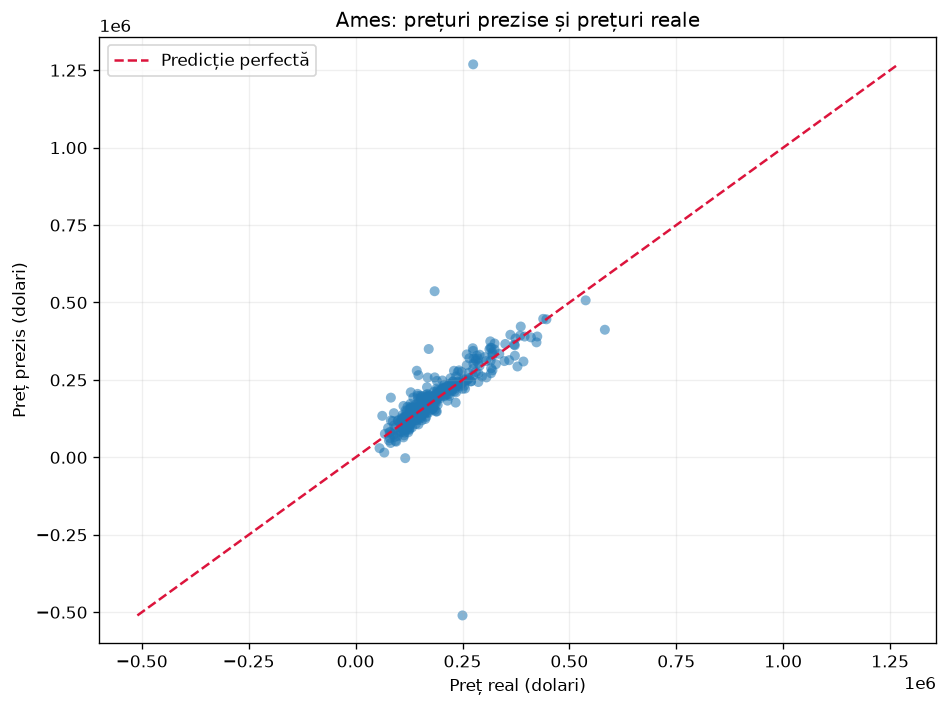

Model: ('One-hot', 'log1p', 'StandardScaler')
RMSE test: 70619.41175315739
MAE test: 25626.324987159707
R² test: 0.1738985065572397


In [6]:
# Model fixat pentru ilustrare, fără alegerea scalerului după eroarea pe test.
plot_key = ('One-hot', 'log1p', 'StandardScaler')
y_pred = predictions[plot_key]
print('Model:', plot_key)
print('RMSE test:', np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAE test:', mean_absolute_error(y_test,y_pred))
print('R² test:', r2_score(y_test,y_pred))
fig, ax = plt.subplots(figsize=(8,6))
ax.scatter(y_test, y_pred, alpha=.55, edgecolors='none')
low = min(y_test.min(), y_pred.min()); high = max(y_test.max(),y_pred.max())
ax.plot([low,high],[low,high], '--', color='crimson', label='Predicție perfectă')
ax.set(xlabel='Preț real (dolari)', ylabel='Preț prezis (dolari)',
       title='Ames: prețuri prezise și prețuri reale')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()


Punctele apropiate de diagonală indică predicții precise. Deasupra diagonalei modelul supraestimează prețul, iar dedesubt îl subestimează. Abaterile mari la anumite locuințe arată limitele unui model liniar și influența observațiilor atipice. Un model prea simplu poate avea bias ridicat, iar unul prea flexibil poate avea varianță ridicată; compararea erorilor de train și de validare ajută la identificarea acestui compromis.

Graficul include toate observațiile de test. Unele estimări sunt negative sau mult prea mari: regresia liniară nu impune automat prețuri pozitive. Nu am eliminat aceste puncte, deoarece ele contribuie la eroarea raportată.